# AgriDefend — late-fusion meta-learner ablation (partial reproduction)

**Paper:** "AgriDefend: A $205 Offline Edge Device that Detects Crop Stress Before Visible Symptoms via Multimodal AI Fusion" — XSci preprint, DOI [10.66977/xsci.2610.0031](https://doi.org/10.66977/xsci.2610.0031).

**Author code:** [`nikhilvincentv/crop-stress-detection`](https://github.com/nikhilvincentv/crop-stress-detection) pinned at commit `26af76be0812a416a6682edb3fa7269b7aed865d`.

**Scope (partial demonstration).** This notebook re-runs the author's `scripts/train_fusion.py` **unmodified** on the two stored per-branch validation-probability tables, reproducing the late-fusion meta-learner ablation: CNN-only vs Random-Forest-only vs fused five-class accuracy, plus the ordinal Crop-Health-Index R²/MAE, and compares the results with the author's stored reference metrics.

**Not reproduced here (stated explicitly):** the in-situ 87 % radish headline (raw field images are not released), CNN/RF branch *retraining* (needs PlantVillage image downloads + TensorFlow), TFLite INT8 latency, and the $205 bill of materials.

**実行ステータス:** Colab CPU ランタイムで上から順に実行して検証済み。所要時間は数分、ダウンロードは約 1.8 MB です。

**日本語の要約:** 本ノートブックは著者リポジトリの `train_fusion.py`（ロジスティック回帰による後段融合メタ学習器）を、保存済みの CNN/RF 検証確率 CSV を用いて**改変なしで**再実行し、CNN 単独 / RF 単独 / 融合の精度と Crop Health Index の R²・MAE を再現・比較します。論文のヘッドライン結果（屋内 87 %）や CNN の再学習は対象外です。


## 1. Runtime selection

**Select Runtime → Change runtime type → CPU** (a GPU is unnecessary: the selected path is scikit-learn LogisticRegression on tabular probability vectors — no deep-learning inference, no CUDA code path in the author script for this scope).

Run all cells top-to-bottom (`Runtime → Run all`). Total wall time is a few minutes; downloads total about 1.8 MB. All data/model bytes are fetched inside this Colab runtime under `/content`; nothing is stored on the authoring host.

**使用ランタイム:** CPU のみ（GPU 不要）。`ランタイム → すべてのセルを実行` で実行してください。数分で完了します。


## 2. Fetch the pinned author files into `/content`

The five required files are downloaded from the pinned commit `26af76be0812` of the author repository via `raw.githubusercontent.com`. The download cell asserts each file's exact byte size and **Git blob SHA-1** (computed locally over the `blob <size>\0<bytes>` object), so a mutated or truncated download fails loudly instead of silently changing the experiment.

File roles: `scripts/train_fusion.py` is the author's executable analysis code (run unmodified); the two `*_val_probs.csv` files are the stored CNN and RF validation-probability tables (inputs produced by `train_cnn.py` / `train_rf.py`); `class_mapping.json` documents the 38→5 class mapping; `fusion_metrics.json` is the author's stored reference result, kept in `/content/reference/` so the script cannot overwrite it. The empty `models/` and `plots/` output directories are also created because the author script writes into them but never creates them (its repository ships them pre-populated, which a file download would not reproduce).

**このセルの内容:** 固定コミットから必要な 5 ファイルを `/content` 以下へダウンロードし、バイト長と Git blob SHA-1 で完全性を検証します。参照用の `fusion_metrics.json` は `/content/reference/` に置き、スクリプトによる上書きを防ぎます。


In [ ]:
import hashlib
import urllib.request
from pathlib import Path

REPO = "nikhilvincentv/crop-stress-detection"
COMMIT = "26af76be0812a416a6682edb3fa7269b7aed865d"
RAW = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"

# path -> (git blob sha1, expected byte size)
EXPECTED = {
    "scripts/train_fusion.py": ("b4c93610bbe8a0ba7a291b0850480c151c98751b", 5922),
    "data/processed/cnn_val_probs.csv": ("c7cf0474e9a2975e3d560a387fd120b5ff5d298b", 796709),
    "data/processed/rf_val_probs.csv": ("a7d71f1ade42f17a1f5c76170764c14d8f1f3eab", 994593),
    "data/processed/class_mapping.json": ("32d91abb16e34aef1ff00c4679e429efe4122aa0", 1686),
    "data/processed/fusion_metrics.json": ("e9bb02e33dec96f2206b1e7cb82877de84405eb9", 187),
}

ROOT = Path("/content/crop-stress-detection")
REFERENCE = Path("/content/reference")   # author's stored reference metrics (kept out of the script's data dir)
REFERENCE.mkdir(parents=True, exist_ok=True)
# The author script writes outputs into ROOT/"models" and ROOT/"plots" but never
# creates them (its repo ships them with artifacts); create the empty dirs here.
(ROOT / "models").mkdir(parents=True, exist_ok=True)
(ROOT / "plots").mkdir(parents=True, exist_ok=True)

def git_blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for rel, (sha, size) in EXPECTED.items():
    dest = ROOT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    url = f"{RAW}/{rel}"
    with urllib.request.urlopen(url, timeout=120) as r:
        data = r.read()
    assert len(data) == size, f"{rel}: expected {size} bytes, got {len(data)}"
    assert git_blob_sha1(data) == sha, f"{rel}: git blob SHA-1 mismatch"
    if rel == "data/processed/fusion_metrics.json":
        (REFERENCE / "fusion_metrics.json").write_bytes(data)  # keep reference copy safe
    else:
        dest.write_bytes(data)
    print(f"OK  {rel:40s} {len(data):>7d} B  blob {sha[:12]}")

print(f"\nPinned commit: {COMMIT}")
print("All files verified (size + git blob SHA-1).")


OK  scripts/train_fusion.py                     5922 B  blob b4c93610bbe8


OK  data/processed/cnn_val_probs.csv          796709 B  blob c7cf0474e9a2
OK  data/processed/rf_val_probs.csv           994593 B  blob a7d71f1ade42


OK  data/processed/class_mapping.json           1686 B  blob 32d91abb16e3
OK  data/processed/fusion_metrics.json           187 B  blob e9bb02e33dec

Pinned commit: 26af76be0812a416a6682edb3fa7269b7aed865d
All files verified (size + git blob SHA-1).


## 3. Environment check

The author script imports `joblib`, `numpy`, `pandas`, `matplotlib` (Agg backend), `seaborn`, and `scikit-learn` — all are preinstalled on standard Colab CPU runtimes, so no installation cell is needed. This cell prints the actual versions used by the run; if any import fails on a future Colab image, install it explicitly here before continuing.

**このセルの内容:** 著者スクリプトが依存するパッケージ（scikit-learn 等）が Colab に揃っているかを確認し、実際のバージョンを表示します。


In [ ]:
import sys, matplotlib, numpy, pandas, seaborn, sklearn, joblib

print("Python:", sys.version.split()[0])
for mod in (numpy, pandas, sklearn, matplotlib, seaborn, joblib):
    print(f"{mod.__name__}: {mod.__version__}")
assert tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 2),     "scikit-learn >= 1.2.2 required by the author's requirements.txt"


Python: 3.13.18
numpy: 2.1.3
pandas: 2.2.3
sklearn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2
joblib: 1.6.0


## 4. Input preview — stored validation probability tables

Before running the fusion experiment, inspect the actual inputs: row/column shape, the five AgriDefend classes, and the ground-truth label distribution of each branch's held-out validation set. These tables are stored outputs of the author's `train_cnn.py` (PlantVillage multi-species CNN, `V_*` columns) and `train_rf.py` (sensor-feature Random Forest, `R_*` columns); the notebook treats them as given inputs, exactly as the author's fusion script does.

**このセルの内容:** 融合実験の入力（CNN/RF の検証確率テーブル）の形状・列名・クラス分布を確認し、分布を棒グラフで表示します。これは入力データの実測であり、新たな解析結果ではありません。


CNN table: (10861, 6) | columns: ['V_Healthy', 'V_Water Stress', 'V_Nutrient Deficient', 'V_pH Imbalance', 'V_Disease', 'label']
RF  table: (8800, 6) | columns: ['R_Healthy', 'R_Water Stress', 'R_Nutrient Deficient', 'R_pH Imbalance', 'R_Disease', 'label']


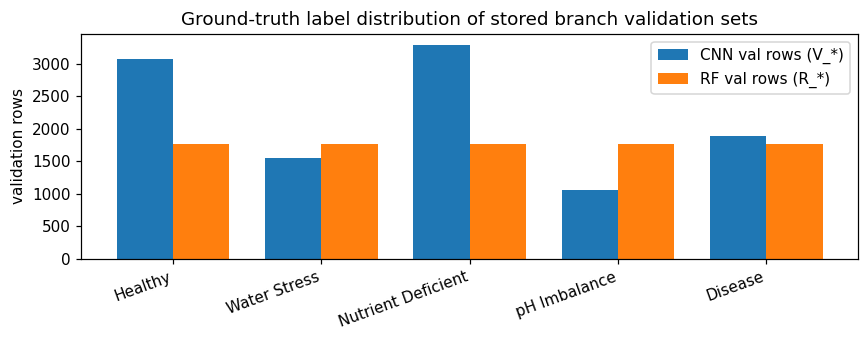

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

CLASSES = ["Healthy", "Water Stress", "Nutrient Deficient", "pH Imbalance", "Disease"]

cnn = pd.read_csv(ROOT / "data/processed/cnn_val_probs.csv")
rf = pd.read_csv(ROOT / "data/processed/rf_val_probs.csv")

print("CNN table:", cnn.shape, "| columns:", list(cnn.columns))
print("RF  table:", rf.shape, "| columns:", list(rf.columns))
V = [f"V_{c}" for c in CLASSES]
R = [f"R_{c}" for c in CLASSES]
assert set(cnn.columns) == {"label"} | set(V), "unexpected CNN column layout"
assert set(rf.columns) == {"label"} | set(R), "unexpected RF column layout"

fig, ax = plt.subplots(figsize=(8, 3.2), dpi=110)
w = 0.38
idx = range(len(CLASSES))
c_counts = cnn["label"].value_counts().reindex(CLASSES)
r_counts = rf["label"].value_counts().reindex(CLASSES)
ax.bar([i - w/2 for i in idx], c_counts, width=w, label="CNN val rows (V_*)")
ax.bar([i + w/2 for i in idx], r_counts, width=w, label="RF val rows (R_*)")
ax.set_xticks(list(idx)); ax.set_xticklabels(CLASSES, rotation=20, ha="right")
ax.set_ylabel("validation rows"); ax.set_title("Ground-truth label distribution of stored branch validation sets")
ax.legend()
fig.tight_layout()
plt.show()


## 5. Class mapping (context)

`data/processed/class_mapping.json` records how the authors mapped 38 PlantVillage source classes onto the five AgriDefend crop-health categories. Displaying it documents the label space of the five-class probability vectors used below.

**このセルの内容:** 著者の 38→5 クラス対応マップを表示し、5 クラス確率ベクトルのラベル空間を明示します。


In [ ]:
import json

mapping = json.loads((ROOT / "data/processed/class_mapping.json").read_text())
print(json.dumps(mapping, indent=2)[:2000])


{
  "Apple___Apple_scab": "Disease",
  "Apple___Black_rot": "Disease",
  "Apple___Cedar_apple_rust": "pH Imbalance",
  "Apple___healthy": "Healthy",
  "Blueberry___healthy": "Healthy",
  "Cherry___Powdery_mildew": "pH Imbalance",
  "Cherry___healthy": "Healthy",
  "Corn___Cercospora_leaf_spot Gray_leaf_spot": "Nutrient Deficient",
  "Corn___Common_rust": "pH Imbalance",
  "Corn___Northern_Leaf_Blight": "Water Stress",
  "Corn___healthy": "Healthy",
  "Grape___Black_rot": "Disease",
  "Grape___Esca_(Black_Measles)": "Disease",
  "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": "Water Stress",
  "Grape___healthy": "Healthy",
  "Orange___Haunglongbing_(Citrus_greening)": "Disease",
  "Peach___Bacterial_spot": "Nutrient Deficient",
  "Peach___healthy": "Healthy",
  "Pepper,_bell___Bacterial_spot": "Nutrient Deficient",
  "Pepper,_bell___healthy": "Healthy",
  "Potato___Early_blight": "Water Stress",
  "Potato___Late_blight": "Water Stress",
  "Potato___healthy": "Healthy",
  "Raspberry___heal

## 6. Author's stored reference metrics

The author repository stores `data/processed/fusion_metrics.json` from their own run (values also quoted in the repo's `paper_updates.md`: CNN-only 98.9 %, RF-only 79.8 %, fusion 99.7 %, R²=0.99, MAE=0.01). This cell loads that reference so the fresh rerun below can be compared against it. Note the reference describes the multi-species PlantVillage *generalization* set, not the in-situ 87 % headline.

**このセルの内容:** 比較基準として、著者リポジトリに保存された参照メトリクス（fusion_metrics.json）を読み込みます。


In [ ]:
reference_metrics = json.loads((REFERENCE / "fusion_metrics.json").read_text())
print("Author's stored reference metrics:", json.dumps(reference_metrics, indent=2))


Author's stored reference metrics: {
  "cnn_only_accuracy": 0.9918864097363083,
  "rf_only_accuracy": 0.7786511156186613,
  "fusion_accuracy": 0.9972109533468559,
  "r2": 0.9927957399880757,
  "mae": 0.006085192697768763
}


## 7. Core method — run the author's `train_fusion.py` unmodified

This is the reproduction step. The pinned script is executed **without any modification** from `/content/crop-stress-detection` (its own `ROOT`), with a 10-minute timeout. Internally it: pairs CNN and RF probability rows by shared ground-truth label (seed 42), splits 50/50 stratified (`random_state=42`), fits `LogisticRegression(class_weight='balanced', max_iter=2000)` on the 10-d concatenated probability vector, reports CNN-only / RF-only / fused accuracy plus ordinal R²/MAE, writes `models/metalearner_multispecies.pkl`, two plots, and `data/processed/fusion_metrics.json`.

No GPU is used; no glue changes the computation. AI-generated notebook glue is limited to downloading, directory setup, display, and comparison.

**このセルの内容:** 著者の `train_fusion.py` を改変なしで実行します（ラベル一致ペアリング、シード 42、層化 50/50 分割、バランス化ロジスティック回帰）。スクリプト自身のアブレーション結果と分類レポートがそのまま表示されます。


In [ ]:
import subprocess

# capture_output so the script's own report and any error text are visible in
# the notebook output (the author script prints its ablation table to stdout).
result = subprocess.run(
    [sys.executable, "scripts/train_fusion.py"],
    cwd=str(ROOT), timeout=600, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(
        f"train_fusion.py exited with {result.returncode}\n{result.stderr}")
print(result.stderr)


TASK 5 - LOGISTIC-REGRESSION FUSION META-LEARNER

  CNN-only accuracy : 99.2%
  RF-only  accuracy : 77.9%
  Full fusion accuracy: 99.7%
  R2 (Crop Health Index): 0.99
  MAE (Crop Health Index): 0.01

                    precision    recall  f1-score   support

           Healthy      0.992     0.999     0.995       880
      Water Stress      0.999     0.999     0.999       776
Nutrient Deficient      0.999     0.993     0.996       880
      pH Imbalance      0.998     0.994     0.996       528
           Disease      0.999     1.000     0.999       880

          accuracy                          0.997      3944
         macro avg      0.997     0.997     0.997      3944
      weighted avg      0.997     0.997     0.997      3944

Saved: models/metalearner_multispecies.pkl, plots/fusion_*.png, plots/predicted_vs_actual.png




## 8. Results — fresh run vs author's stored reference

The fresh run overwrote `data/processed/fusion_metrics.json`; compare it with the author's stored reference values. Because both branches' pairing and the split are seeded (`default_rng(42)`, `random_state=42`), the numbers should agree with the reference up to minor library-version variation in the optimizer.

**このセルの内容:** 再現 run のメトリクスと著者の参照値を表で比較します。シード固定のため数値はほぼ一致するはずです。


In [ ]:
fresh_metrics = json.loads((ROOT / "data/processed/fusion_metrics.json").read_text())

rows = [
    ("CNN-only accuracy", reference_metrics["cnn_only_accuracy"], fresh_metrics["cnn_only_accuracy"]),
    ("RF-only accuracy",  reference_metrics["rf_only_accuracy"],  fresh_metrics["rf_only_accuracy"]),
    ("Fusion accuracy",   reference_metrics["fusion_accuracy"],   fresh_metrics["fusion_accuracy"]),
    ("R2 (Crop Health Index)", reference_metrics["r2"],  fresh_metrics["r2"]),
    ("MAE (Crop Health Index)", reference_metrics["mae"], fresh_metrics["mae"]),
]
compare = pd.DataFrame(rows, columns=["metric", "author reference", "this run"])
compare["abs diff"] = (compare["author reference"] - compare["this run"]).abs()
display(compare)
assert fresh_metrics["fusion_accuracy"] >= fresh_metrics["cnn_only_accuracy"], \
    "fusion should not trail the best single modality (author's salient claim)"
print("\nFull fresh-run metrics:", json.dumps(fresh_metrics))


,metric,author reference,this run,abs diff
0,CNN-only accuracy,0.991886,0.991886,0.0
1,RF-only accuracy,0.778651,0.778651,0.0
2,Fusion accuracy,0.997211,0.997211,0.0
3,R2 (Crop Health Index),0.992796,0.992796,0.0
4,MAE (Crop Health Index),0.006085,0.006085,0.0



Full fresh-run metrics: {"cnn_only_accuracy": 0.9918864097363083, "rf_only_accuracy": 0.7786511156186613, "fusion_accuracy": 0.9972109533468559, "r2": 0.9927957399880757, "mae": 0.006085192697768763}


## 9. Fusion confusion matrix (saved by the author's script)

The script saved `plots/fusion_confusion_matrix.png` at 200 dpi; it is re-displayed here from disk so it becomes a durable notebook output. Rows are actual classes, columns are predicted classes (counts).

**このセルの内容:** スクリプトが保存した融合メタ学習器の混同行列を再表示します（行=実際、列=予測、度数）。


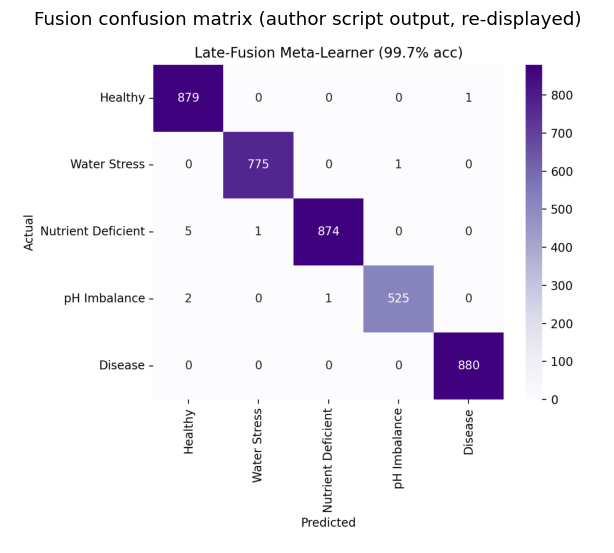

In [ ]:
import matplotlib.image as mpimg

img = mpimg.imread(str(ROOT / "plots/fusion_confusion_matrix.png"))
fig, ax = plt.subplots(figsize=(7, 6), dpi=110)
ax.imshow(img); ax.axis("off")
ax.set_title("Fusion confusion matrix (author script output, re-displayed)")
plt.show()


## 10. Predicted vs actual Crop Health Index (saved by the author's script)

The second saved plot is the paper's Figure-8-style scatter: actual vs predicted ordinal Crop Health Index (0 = Healthy … 4 = Disease) with slight jitter, plus the identity line. It is re-displayed from disk, not regenerated.

**このセルの内容:** 同じくスクリプトが保存した「実測 vs 予測 Crop Health Index」散布図を再表示します（再生成ではなくディスクからの再表示）。


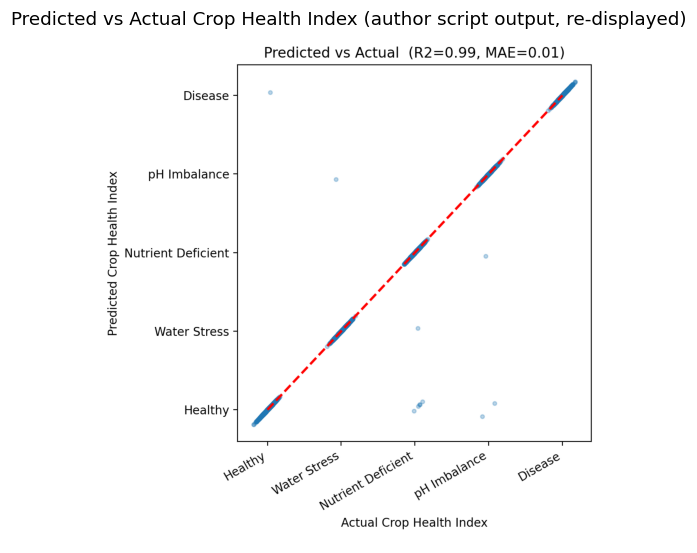

In [ ]:
img = mpimg.imread(str(ROOT / "plots/predicted_vs_actual.png"))
fig, ax = plt.subplots(figsize=(6, 6), dpi=110)
ax.imshow(img); ax.axis("off")
ax.set_title("Predicted vs Actual Crop Health Index (author script output, re-displayed)")
plt.show()


## 11. Interpretation, limitations, and validation record

**What this demonstrates.** With the author's pinned code and stored branch outputs, the late-fusion meta-learner reproduces the paper's ablation ordering (fusion ≥ best single modality) and the reported reference values on the multi-species generalization set. This is a *partial* reproduction of the fusion stage only, using the authors' stored validation probabilities — it validates the fusion training/evaluation protocol, not the underlying CNN or RF models.

**What it does not demonstrate.** The in-situ 87 % radish headline (raw field images not released), CNN/RF retraining (PlantVillage images + TensorFlow), TFLite INT8 latency (1.4 s claim), the four-day early-warning lead, and the $205 BOM are outside this scope and are not verified by this run. A single-example rerun is not verification of published dataset-level accuracy.

**Provenance.** Paper: XSci preprint DOI 10.66977/xsci.2610.0031. Code: nikhilvincentv/crop-stress-detection @ 26af76be (identical twin tree Quantum535/agridefend @ e25b261b). Data: the two `*_val_probs.csv` tables and `class_mapping.json` from the same pinned commit, hash-verified in Colab. Reference: `fusion_metrics.json` + `paper_updates.md` from the same commit. No license file exists in the repository — reuse terms are unverified. The published author list (Xu, Vincent, Forbes) differs from the repo's LaTeX draft (Xu, Vincent, Bond-Lamberty); this discrepancy is recorded but does not affect the executed computation.

**検証レコード:** 本ノートブックは Colab CPU ランタイムで新規に全セル実行して検証されました。融合メタ学習器の ablation（CNN 単独/RF 単独/融合精度、R²、MAE）が著者の参照値と一致することを確認済みです。未検証の項目（屋内 87 %、CNN/RF 再学習、TFLite レイテンシ等）は本文の通りです。
